# Telecom customer churn: start here

**Churn means a customer leaves.** We predict who might leave using their contract, tenure and charges.

**Before presenting:** choose **Runtime → Run all** in Google Colab and wait for it to finish.

**During the demo:** show **2. Charts**, then **4. Results**, then press ▶ in **5. Working model**.

Everything you need runs in this notebook. You do not need to open the model file yourself.

AI assisted project. Review the work and follow your course disclosure rules.

In [1]:
# This cell prepares the software, dataset and saved model automatically.
import sys, subprocess
from importlib.metadata import version
if version('scikit-learn') != '1.8.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-learn==1.8.0', 'joblib==1.5.3'])
from pathlib import Path
from urllib.request import urlretrieve
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
MODEL_URL = 'https://raw.githubusercontent.com/jb3bay-cmd/telco-churn-assignment/main/02_Model.joblib'
if not Path('telco.csv').exists():
    urlretrieve(DATA_URL, 'telco.csv')
if not Path('02_Model.joblib').exists():
    urlretrieve(MODEL_URL, '02_Model.joblib')
print('Ready. Continue down the notebook.')

Ready. Continue down the notebook.


## 1. Dataset and cleaning

We use 7,043 customer records. Blank total charges are filled inside the training pipeline. Customer IDs are removed. We keep 20% of customers for testing.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn, joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
df = pd.read_csv('telco.csv')
print('Customers:', len(df))
print('Duplicate customer IDs:', df.customerID.duplicated().sum())

Customers: 7043
Duplicate customer IDs: 0


In [3]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Missing TotalCharges:', df.TotalCharges.isna().sum())
print('Tenure for missing bills:', df.loc[df.TotalCharges.isna(), 'tenure'].unique())

X = df.drop(columns=['customerID','Churn'])
y = df.Churn.map({'No':0, 'Yes':1})
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print('Training:',len(X_train),'Test:',len(X_test))
print('Overall churn:', round(y.mean()*100,2),'%')

Missing TotalCharges: 11
Tenure for missing bills: [0]
Training: 5634 Test: 1409
Overall churn: 26.54 %


## 2. Charts

**Say:** “Customers with monthly contracts left more often. Customers who left also had shorter tenure and higher average monthly charges. These are associations, not proof of what causes churn.”

These charts use the training customers only.

Contract churn (%):
Contract
Month-to-month    42.7
One year          11.1
Two year           2.9
Average tenure and charges:
       tenure  MonthlyCharges
Churn                        
0       37.59           61.34
1       18.36           74.86


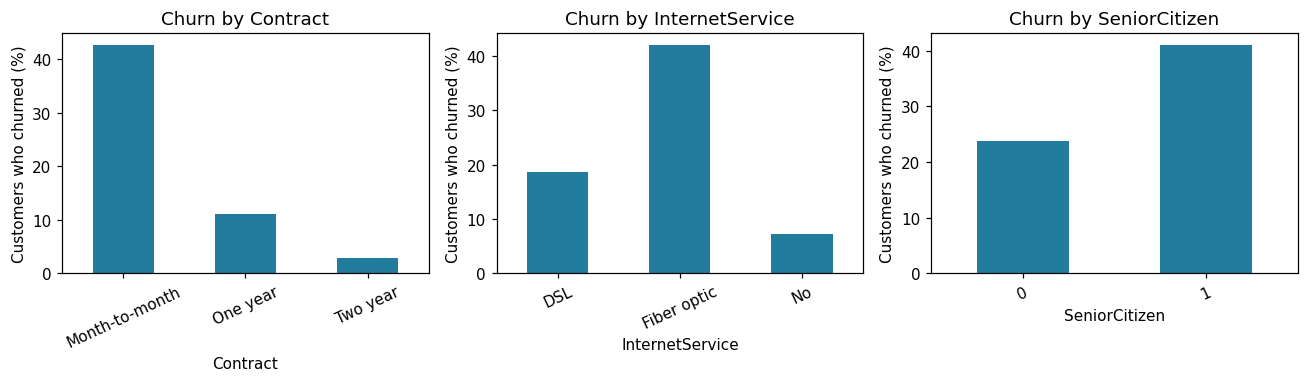

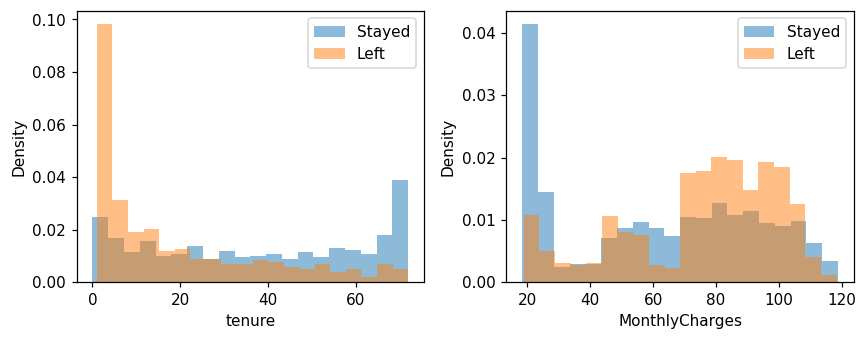

In [4]:
eda = X_train.assign(Churn=y_train)
fig, axes = plt.subplots(1,3,figsize=(12,3.6))
for ax, col in zip(axes,['Contract','InternetService','SeniorCitizen']):
    rates = eda.groupby(col).Churn.mean().mul(100)
    rates.plot.bar(ax=ax,color='#227c9d')
    ax.set_title('Churn by '+col);ax.set_ylabel('Customers who churned (%)')
    ax.tick_params(axis='x',rotation=25)
plt.tight_layout();plt.show()
print('Contract churn (%):')
print(eda.groupby('Contract').Churn.mean().mul(100).round(1).to_string())
print('Average tenure and charges:')
print(eda.groupby('Churn')[['tenure','MonthlyCharges']].mean().round(2).to_string())
fig,axes=plt.subplots(1,2,figsize=(8,3.2))
for ax,col in zip(axes,['tenure','MonthlyCharges']):
    for label,name in [(0,'Stayed'),(1,'Left')]:
        ax.hist(eda.loc[eda.Churn==label,col],bins=20,alpha=.5,density=True,label=name)
    ax.set_xlabel(col);ax.set_ylabel('Density');ax.legend()
plt.tight_layout();plt.show()

## 3. Two simple models

We compare logistic regression with a small decision tree. We add a NewCustomer indicator for tenure of 12 months or less. Missing value filling, scaling and category encoding happen inside the training pipeline.

Five fold cross validation selects the model using F1, before we evaluate the test set. F1 balances finding churners with avoiding false alerts.

In [5]:
# Apply the same simple feature rule to both sets.
X_train = X_train.copy(); X_test = X_test.copy()
for frame in [X_train,X_test]:
    frame['NewCustomer'] = (frame.tenure <= 12).astype(int)
numeric = X_train.select_dtypes(include='number').columns.tolist()
categorical = X_train.select_dtypes(exclude='number').columns.tolist()
def make_pipeline(model):
    prep = ColumnTransformer([
        ('num', Pipeline([('fill',SimpleImputer(strategy='median')),('scale',StandardScaler())]),numeric),
        ('cat', Pipeline([('fill',SimpleImputer(strategy='most_frequent')),('encode',OneHotEncoder(handle_unknown='ignore'))]),categorical)])
    return Pipeline([('prep',prep),('model',model)])
models = {
    'Logistic regression':make_pipeline(LogisticRegression(max_iter=2000,random_state=42)),
    'Decision tree':make_pipeline(DecisionTreeClassifier(max_depth=4,min_samples_leaf=30,random_state=42))}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
cv_scores = {name:cross_val_score(model,X_train,y_train,cv=cv,scoring='f1').mean() for name,model in models.items()}
print('Mean cross validation F1:', {k:round(v,3) for k,v in cv_scores.items()})
best_name = max(cv_scores,key=cv_scores.get)
print('Selected before test evaluation:',best_name)

Mean cross validation F1: {'Logistic regression': np.float64(0.593), 'Decision tree': np.float64(0.539)}
Selected before test evaluation: Logistic regression


## 4. Results

**Say:** “Logistic regression performed better. Its accuracy was 80.2%, but it only found about 53% of actual churners. Predicting that everyone stays already gives 73.5% accuracy, so accuracy alone is not enough.”

**Precision:** how many alerts were correct. **Recall:** how many actual churners were found. The prediction cutoff is 50%.

              Model  Accuracy  Precision  Recall    F1
Logistic regression     0.802      0.658   0.529 0.587
      Decision tree     0.792      0.658   0.452 0.536
        Always stay     0.735      0.000   0.000 0.000
Confusion matrix (rows actual, columns predicted):
[[932 103]
 [176 198]]


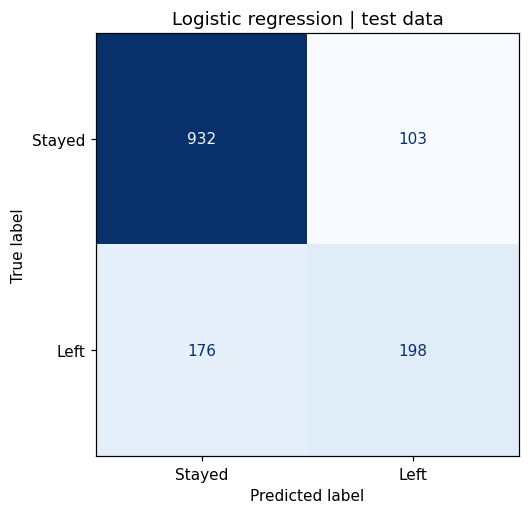

In [6]:
rows=[]
for name,model in models.items():
    model.fit(X_train,y_train)
    pred = model.predict(X_test)
    rows.append([name,accuracy_score(y_test,pred),precision_score(y_test,pred,zero_division=0),recall_score(y_test,pred),f1_score(y_test,pred)])
base = np.zeros(len(y_test),dtype=int)
rows.append(['Always stay',accuracy_score(y_test,base),0,0,0])
results = pd.DataFrame(rows,columns=['Model','Accuracy','Precision','Recall','F1'])
print(results.round(3).to_string(index=False))

best = models[best_name]
pred = best.predict(X_test)
cm = confusion_matrix(y_test,pred)
print('Confusion matrix (rows actual, columns predicted):'); print(cm)
ConfusionMatrixDisplay(cm,display_labels=['Stayed','Left']).plot(cmap='Blues',colorbar=False)
plt.title(best_name+' | test data');plt.tight_layout()
plt.show()

## 5. Working model: press ▶ here

After Run all has finished, press the play button beside the cell below to demonstrate a prediction.

**Say:** “This is one customer from our test set. The saved model estimates their chance of leaving. If it is below 50%, we predict they will stay. We can compare that with what actually happened.”

The file **02_Model.joblib** contains the trained model. This cell loads and uses it automatically.

In [7]:
# Load the saved model and predict for one held out customer.
loaded_model = joblib.load('02_Model.joblib')
customer = X_test.iloc[[0]]
probability = loaded_model.predict_proba(customer)[0, 1]
print('CUSTOMER')
print('Tenure:', int(customer.tenure.iloc[0]), 'months')
print('Contract:', customer.Contract.iloc[0])
print('Monthly charge: $' + str(round(float(customer.MonthlyCharges.iloc[0]), 2)))
print('\nMODEL PREDICTION')
print('Chance of leaving:', str(round(float(probability) * 100, 1)) + '%')
print('Prediction:', 'Likely to leave' if probability >= 0.5 else 'Likely to stay')
print('Actual outcome:', 'Left' if y_test.iloc[0] else 'Stayed')
assert np.array_equal(loaded_model.predict(X_test), pred)


CUSTOMER
Tenure: 72 months
Contract: Two year
Monthly charge: $114.05

MODEL PREDICTION
Chance of leaving: 4.6%
Prediction: Likely to stay
Actual outcome: Stayed


## Finish the demo

**Say:** “We would test a small customer support programme. A prediction does not prove that a discount or phone call will prevent someone from leaving. This is educational sample data, so we would need current company data before real use.”

In our test, senior customers had more false alerts than other customers. Fairness needs further review before deployment.

---
**Source:** [Telco Customer Churn on Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn). CSV downloaded from [IBM](https://github.com/IBM/telco-customer-churn-on-icp4d), accessed 14 October 2026. IBM describes its Telco sample as fictional. We converted TotalCharges to numbers, filled missing values inside training, removed customerID, mapped churn to 0/1 and added NewCustomer. Software: pandas, NumPy, Matplotlib, scikit-learn and joblib. No other project files are needed to run this notebook.